In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "3"

import torch, time, torchattacks, random, argparse
import numpy as np
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import torchvision as tv
import torch.nn as nn
from robustbench.data import load_cifar10, load_imagenet
from robustbench.utils import clean_accuracy, load_model

device = torch.device("cuda")

# 设置seed
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(777)

x_test, y_test = load_imagenet(n_examples=512, data_dir='/home/data-3/Imagenet1K')
x_test = x_test.to(device)
y_test = y_test.to(device)

test_loader = DataLoader(
    torch.utils.data.TensorDataset(x_test, y_test),
    batch_size=32,
    shuffle=False
)

# transform_train = transforms.Compose([
#      transforms.Resize(256),
#      transforms.RandomHorizontalFlip(),
#      transforms.ToTensor(),
# #      transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
# ])

# transform_test = transforms.Compose([
#      transforms.Resize(256),
#      transforms.ToTensor(),
# #      transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
# ])


model = load_model('Standard_R50', dataset='imagenet').to(device)
atk1 = torchattacks.AutoAttack(model, eps=1, norm='L2')

acc=0
acc_atk1=0

CEs = []
AEs = []


for i, data in enumerate(test_loader, 0):
    inputs, labels = data
    inputs, labels = inputs.to(device), labels.to(device)
    adv_inputs1 = atk1(inputs, labels)

    CEs.append(inputs.clone().detach().cpu().numpy())
    AEs.append(adv_inputs1.clone().detach().cpu().numpy())


    _, preds = torch.max(model(inputs), 1)
    _, preds_atk1 = torch.max(model(adv_inputs1), 1)

    acc += torch.sum(preds == labels).item()
    acc_atk1 += torch.sum(preds_atk1 == labels).item()
    # break

print("test acc on clean examples (%): {:.2f}".format(
        acc / 512. * 100.0))
print("test acc on FGSM examples (%):  {:.2f}".format(
        acc_atk1 / 512. * 100.0))


/home/lin/miniforge3/envs/putt/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/lin/miniforge3/envs/putt/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/lin/miniforge3/envs/putt/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


test acc on clean examples (%): 76.76
test acc on FGSM examples (%):  0.00


In [2]:
AEs = np.array(AEs)
CEs = np.array(CEs)
print(AEs.shape)
print(CEs.shape)
AEs = AEs.reshape(-1, 3, 224, 224)
CEs = CEs.reshape(-1, 3, 224, 224)
print(AEs.shape)
print(CEs.shape)

np.save('./npydata/AEs_imagel2.npy', AEs)

(16, 32, 3, 224, 224)
(16, 32, 3, 224, 224)
(512, 3, 224, 224)
(512, 3, 224, 224)


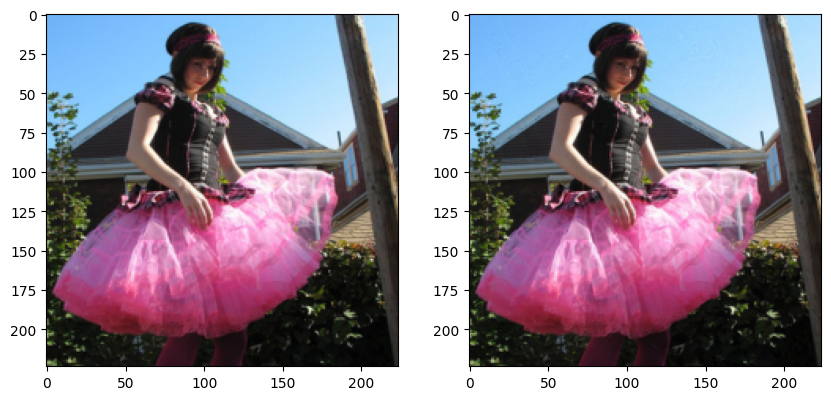

In [3]:
import matplotlib.pyplot as plt

tt_idx = 14
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
x_rec1 = CEs[tt_idx]
x_rec1 = x_rec1.transpose(1, 2, 0)

x_rec2 = AEs[tt_idx]
x_rec2 = x_rec2.transpose(1, 2, 0)


axs[0].imshow(x_rec1)
axs[1].imshow(x_rec2)

plt.show()

In [10]:
x_rec2-x_rec1

array([[[ 7.64608383e-04,  4.89950180e-05, -2.50518322e-04],
        [-1.78366899e-04, -1.33723021e-03, -1.37418509e-03],
        [-7.32630491e-04, -1.37335062e-03, -9.54091549e-04],
        ...,
        [ 6.68764114e-05,  1.83403492e-04,  4.76241112e-05],
        [ 1.94251537e-04,  3.65614891e-04,  0.00000000e+00],
        [-2.27689743e-05,  9.54866409e-05,  0.00000000e+00]],

       [[ 2.09718943e-04, -6.27636909e-04, -4.40597534e-04],
        [-9.44435596e-04, -1.82503462e-03, -2.28321552e-03],
        [ 1.29947066e-03,  1.29812956e-03,  3.51607800e-04],
        ...,
        [ 2.67386436e-04,  3.79025936e-04,  0.00000000e+00],
        [ 2.94089317e-04,  4.45365906e-04,  0.00000000e+00],
        [-1.40845776e-04,  1.74045563e-05, -2.02655792e-06]],

       [[-1.64374709e-03, -1.68120861e-03, -9.76622105e-04],
        [ 1.28772855e-03,  1.77389383e-03,  8.56518745e-04],
        [ 3.74287367e-04,  1.46567822e-04, -7.82847404e-04],
        ...,
        [-1.34825706e-04, -7.70092010e-05,

In [17]:
acc=0
acc_atk1=0
CEs = []
AEs = []
Ys = []
for i, data in enumerate(test_loader, 0):
    inputs, labels = data
    inputs, labels = inputs.to(device), labels.to(device)
    adv_inputs1 = atk1(inputs, labels)

    CEs.append(inputs.clone().detach().cpu().numpy())
    AEs.append(adv_inputs1.clone().detach().cpu().numpy())
    Ys.append(labels.clone().detach().cpu().numpy())


    _, preds = torch.max(model(inputs), 1)
    _, preds_atk1 = torch.max(model(adv_inputs1), 1)

    acc += torch.sum(preds == labels).item()
    acc_atk1 += torch.sum(preds_atk1 == labels).item()

print("test acc on clean examples (%): {:.2f}".format(
        acc / 512. * 100.0))
print("test acc on FGSM examples (%):  {:.2f}".format(
        acc_atk1 / 512. * 100.0))

test acc on clean examples (%): 76.76
test acc on FGSM examples (%):  0.00


In [12]:
AEs = np.array(AEs)
CEs = np.array(CEs)
AEs.shape, CEs.shape

((16, 32, 3, 224, 224), (16, 32, 3, 224, 224))

In [13]:
AEs = np.array(AEs)
CEs = np.array(CEs)
print(AEs.shape, CEs.shape)
AEs = AEs.reshape(-1, 3, 224, 224)
CEs = CEs.reshape(-1, 3, 224, 224)
print(AEs.shape, CEs.shape)

np.save('AEs.npy', AEs)

((512, 3, 224, 224), (512, 3, 224, 224))

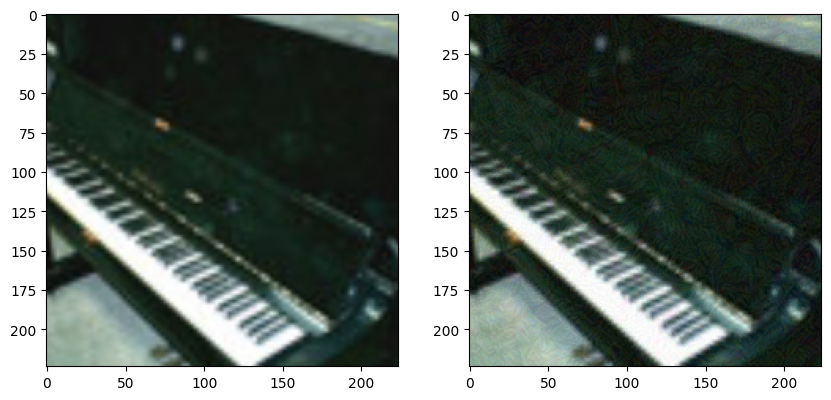

In [15]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
x_rec1 = CEs[24]
x_rec1 = x_rec1.transpose(1, 2, 0)

x_rec2 = AEs[24]
x_rec2 = x_rec2.transpose(1, 2, 0)


axs[0].imshow(x_rec1)
axs[1].imshow(x_rec2)

plt.show()

In [16]:
np.save('CEs.npy', CEs)
np.save('AEs.npy', AEs)

In [20]:
Ys = np.array(Ys)
Ys = Ys.reshape(-1)
Ys.shape

(512,)

In [21]:
np.save('Ys.npy', Ys)

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "5"

import torch, time, torchattacks, random, argparse
import numpy as np
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import torchvision as tv
import torch.nn as nn
from robustbench.data import load_cifar10, load_imagenet
from robustbench.utils import clean_accuracy, load_model
from models.cifar10_resnet import ResNet50
from stadv_eot import stadv

device = torch.device("cuda")

# 设置seed
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(777)

x_test, y_test = load_cifar10(n_examples=512)
x_test = x_test.to(device)
y_test = y_test.to(device)

test_loader = DataLoader(
    torch.utils.data.TensorDataset(x_test, y_test),
    batch_size=32,
    shuffle=False
)

def update_state_dict(state_dict, idx_start=9):

    from collections import OrderedDict
    new_state_dict = OrderedDict()
    for k, v in state_dict.items():
        name = k[idx_start:]  # remove 'module.0.' of dataparallel
        new_state_dict[name]=v

    return new_state_dict


model = ResNet50().to(device)
model_path = 'models/weights.pt'
model.load_state_dict(update_state_dict(torch.load(model_path), idx_start=7))
model.eval()

# atk1 = torchattacks.AutoAttack(model, eps=1, norm='L2')
atk1 = stadv.StAdvAttack(model, bound=0.05, num_iterations=100, eot_iter=20)

acc=0
acc_atk1=0

CEs = []
AEs = []


for i, data in enumerate(test_loader, 0):
    inputs, labels = data
    inputs, labels = inputs.to(device), labels.to(device)
    adv_inputs1 = atk1(inputs, labels)

    CEs.append(inputs.clone().detach().cpu().numpy())
    AEs.append(adv_inputs1.clone().detach().cpu().numpy())


    _, preds = torch.max(model(inputs), 1)
    _, preds_atk1 = torch.max(model(adv_inputs1), 1)

    acc += torch.sum(preds == labels).item()
    acc_atk1 += torch.sum(preds_atk1 == labels).item()
    # break

print("test acc on clean examples (%): {:.2f}".format(
        acc / 512. * 100.0))
print("test acc on FGSM examples (%):  {:.2f}".format(
        acc_atk1 / 512. * 100.0))


/home/lin/miniforge3/envs/putt/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Files already downloaded and verified


/home/lin/miniforge3/envs/putt/lib/python3.10/site-packages/torch/nn/functional.py:4298: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  warnings.warn(


inside PGD attack, eot_iter: 20, max_iterations: 100


/home/lin/miniforge3/envs/putt/lib/python3.10/site-packages/torch/nn/functional.py:4236: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  warnings.warn(


inside PGD attack, eot_iter: 20, max_iterations: 100
inside PGD attack, eot_iter: 20, max_iterations: 100
inside PGD attack, eot_iter: 20, max_iterations: 100
inside PGD attack, eot_iter: 20, max_iterations: 100
inside PGD attack, eot_iter: 20, max_iterations: 100
inside PGD attack, eot_iter: 20, max_iterations: 100
inside PGD attack, eot_iter: 20, max_iterations: 100
inside PGD attack, eot_iter: 20, max_iterations: 100
inside PGD attack, eot_iter: 20, max_iterations: 100
inside PGD attack, eot_iter: 20, max_iterations: 100
inside PGD attack, eot_iter: 20, max_iterations: 100
inside PGD attack, eot_iter: 20, max_iterations: 100
inside PGD attack, eot_iter: 20, max_iterations: 100
inside PGD attack, eot_iter: 20, max_iterations: 100
inside PGD attack, eot_iter: 20, max_iterations: 100
test acc on clean examples (%): 96.09
test acc on FGSM examples (%):  0.00


In [2]:
AEs = np.array(AEs)
CEs = np.array(CEs)
print(AEs.shape, CEs.shape)
AEs = AEs.reshape(-1, 3, 32, 32)
CEs = CEs.reshape(-1, 3, 32, 32)
print(AEs.shape, CEs.shape)

# np.save('./npydata/AEs_cifar_std.npy', AEs)
np.save('./tmp.npy', AEs)

(16, 32, 3, 32, 32) (16, 32, 3, 32, 32)
(512, 3, 32, 32) (512, 3, 32, 32)


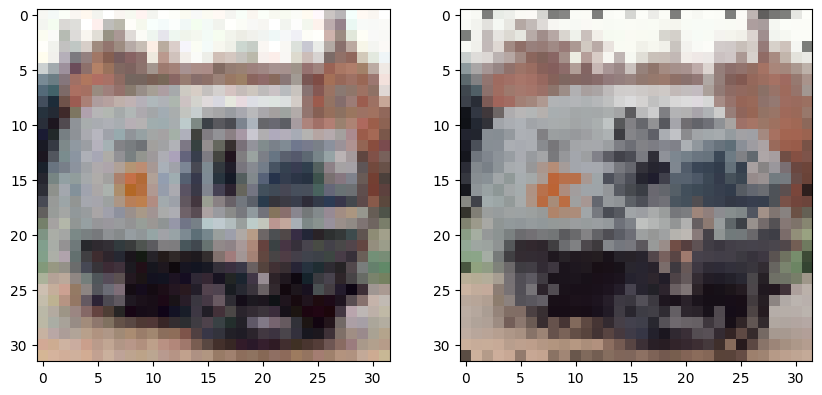

In [2]:
import matplotlib.pyplot as plt
import numpy as np

CEs = np.load('./npydata/AEs_cifar10.npy')

AEs = np.load('./npydata/AEs_cifar_std.npy')


fig, axs = plt.subplots(1, 2, figsize=(10, 5))
x_rec1 = CEs[11]
x_rec1 = x_rec1.transpose(1, 2, 0)

x_rec2 = AEs[11]
x_rec2 = x_rec2.transpose(1, 2, 0)


axs[0].imshow(x_rec1)
axs[1].imshow(x_rec2)

plt.show()

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "5"

import torch, time, torchattacks, random, argparse
import numpy as np
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import torchvision as tv
import torch.nn as nn
from robustbench.data import load_cifar10, load_cifar100, load_imagenet
from robustbench.utils import clean_accuracy, load_model
from models.cifar10_resnet import ResNet50
from stadv_eot import stadv
from models.wrn import wrn

device = torch.device("cuda")

# 设置seed
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(777)

x_test, y_test = load_cifar100(n_examples=512)
x_test = x_test.to(device)
y_test = y_test.to(device)

test_loader = DataLoader(
    torch.utils.data.TensorDataset(x_test, y_test),
    batch_size=32,
    shuffle=False
)

def update_state_dict(state_dict):

    from collections import OrderedDict
    new_state_dict = OrderedDict()
    for k, v in state_dict.items():
        name = k.replace('module.', '')
        new_state_dict[name]=v

    return new_state_dict

model = wrn(num_classes=100, depth=28, widen_factor=10).to(device)

model_path = 'models/checkpoint.pth.tar'
model.load_state_dict(update_state_dict(torch.load(model_path)['state_dict']))
model.eval()

# atk1 = torchattacks.AutoAttack(model, eps=1, norm='L2')
# atk1 = stadv.StAdvAttack(model)

acc=0
acc_atk1=0

CEs = []
AEs = []


for i, data in enumerate(test_loader, 0):
    inputs, labels = data
    inputs, labels = inputs.to(device), labels.to(device)
    # adv_inputs1 = atk1(inputs, labels)
    adv_inputs1 = inputs

    CEs.append(inputs.clone().detach().cpu().numpy())
    AEs.append(adv_inputs1.clone().detach().cpu().numpy())


    _, preds = torch.max(model(inputs), 1)
    _, preds_atk1 = torch.max(model(adv_inputs1), 1)

    acc += torch.sum(preds == labels).item()
    acc_atk1 += torch.sum(preds_atk1 == labels).item()
    # break

print("test acc on clean examples (%): {:.2f}".format(
        acc / 512. * 100.0))
print("test acc on FGSM examples (%):  {:.2f}".format(
        acc_atk1 / 512. * 100.0))


/home/lin/miniforge3/envs/putt/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Files already downloaded and verified
test acc on clean examples (%): 82.03
test acc on FGSM examples (%):  0.00


In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "3"

import torch, time, torchattacks, random, argparse
import numpy as np
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import torchvision as tv
import torch.nn as nn
from robustbench.data import load_cifar10, load_imagenet
from robustbench.utils import clean_accuracy, load_model

device = torch.device("cuda")

# 设置seed
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(777)

x_test, y_test = load_imagenet(n_examples=512, data_dir='/home/data-3/Imagenet1K')
x_test = x_test.to(device)
y_test = y_test.to(device)

test_loader = DataLoader(
    torch.utils.data.TensorDataset(x_test, y_test),
    batch_size=32,
    shuffle=False
)

# transform_train = transforms.Compose([
#      transforms.Resize(256),
#      transforms.RandomHorizontalFlip(),
#      transforms.ToTensor(),
# #      transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
# ])

# transform_test = transforms.Compose([
#      transforms.Resize(256),
#      transforms.ToTensor(),
# #      transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
# ])


model = load_model('Standard_R50', dataset='imagenet').to(device)
atk1 = torchattacks.AutoAttack(model, eps=1, norm='L2')

acc=0
acc_atk1=0

CEs = []
AEs = []


for i, data in enumerate(test_loader, 0):
    inputs, labels = data
    inputs, labels = inputs.to(device), labels.to(device)
    adv_inputs1 = atk1(inputs, labels)

    CEs.append(inputs.clone().detach().cpu().numpy())
    AEs.append(adv_inputs1.clone().detach().cpu().numpy())


    _, preds = torch.max(model(inputs), 1)
    _, preds_atk1 = torch.max(model(adv_inputs1), 1)

    acc += torch.sum(preds == labels).item()
    acc_atk1 += torch.sum(preds_atk1 == labels).item()
    # break

print("test acc on clean examples (%): {:.2f}".format(
        acc / 512. * 100.0))
print("test acc on FGSM examples (%):  {:.2f}".format(
        acc_atk1 / 512. * 100.0))


/home/lin/miniforge3/envs/putt/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/lin/miniforge3/envs/putt/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/lin/miniforge3/envs/putt/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


test acc on clean examples (%): 76.76
test acc on FGSM examples (%):  0.00


In [2]:
AEs = np.array(AEs)
CEs = np.array(CEs)
print(AEs.shape, CEs.shape)
AEs = AEs.reshape(-1, 3, 224, 224)
CEs = CEs.reshape(-1, 3, 224, 224)
print(AEs.shape, CEs.shape)

np.save('./AEs_image4.npy', AEs)

(16, 32, 3, 224, 224) (16, 32, 3, 224, 224)
(512, 3, 224, 224) (512, 3, 224, 224)


In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

import torch, time, torchattacks, random, argparse
import numpy as np
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import torchvision as tv
import torch.nn as nn
from robustbench.data import load_cifar10, load_imagenet
from robustbench.utils import clean_accuracy, load_model

device = torch.device("cuda")

# 设置seed
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(777)

# x_test, y_test = load_imagenet(n_examples=512, data_dir='/home/data-3/Imagenet1K')
x_test, y_test = load_cifar10(n_examples=512)
x_test = x_test.to(device)
y_test = y_test.to(device)

test_loader = DataLoader(
    torch.utils.data.TensorDataset(x_test, y_test),
    batch_size=32,
    shuffle=False
)

# transform_train = transforms.Compose([
#      transforms.Resize(256),
#      transforms.RandomHorizontalFlip(),
#      transforms.ToTensor(),
# #      transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
# ])

# transform_test = transforms.Compose([
#      transforms.Resize(256),
#      transforms.ToTensor(),
# #      transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
# ])


# model = load_model('Standard_R50', dataset='imagenet').to(device)
model = load_model(model_name='Standard', dataset='cifar10', threat_model='Linf').to(device)
atk1 = torchattacks.AutoAttack(model, eps=0.5, norm='L2')

acc=0
acc_atk1=0

CEs = []
AEs = []


for i, data in enumerate(test_loader, 0):
    inputs, labels = data
    inputs, labels = inputs.to(device), labels.to(device)
    adv_inputs1 = atk1(inputs, labels)

    CEs.append(inputs.clone().detach().cpu().numpy())
    AEs.append(adv_inputs1.clone().detach().cpu().numpy())


    _, preds = torch.max(model(inputs), 1)
    _, preds_atk1 = torch.max(model(adv_inputs1), 1)

    acc += torch.sum(preds == labels).item()
    acc_atk1 += torch.sum(preds_atk1 == labels).item()
    # break

print("test acc on clean examples (%): {:.2f}".format(
        acc / 512. * 100.0))
print("test acc on FGSM examples (%):  {:.2f}".format(
        acc_atk1 / 512. * 100.0))


/home/lin/miniforge3/envs/putt/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Files already downloaded and verified
test acc on clean examples (%): 94.73
test acc on FGSM examples (%):  0.00


In [2]:
AEs = np.array(AEs)
CEs = np.array(CEs)
print(AEs.shape, CEs.shape)
AEs = AEs.reshape(-1, 3, 32, 32)
CEs = CEs.reshape(-1, 3, 32, 32)
print(AEs.shape, CEs.shape)

# np.save('./npydata/AEs_cifar_std.npy', AEs)
np.save('./npydata/AEs_cifarl2.npy', AEs)

(16, 32, 3, 32, 32) (16, 32, 3, 32, 32)
(512, 3, 32, 32) (512, 3, 32, 32)
